<a href="https://colab.research.google.com/github/codewithsuprotim/sms-spam-classifier-nlp/blob/main/SMS_Spam_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import re
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# Download official UCI SMS Spam Collection dataset
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip"
ZIP_PATH = "/content/smsspamcollection.zip"
EXTRACT_DIR = "/content/sms_data"

if not os.path.exists(EXTRACT_DIR):
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(EXTRACT_DIR)

# Load dataset (5,572 messages)
raw_file = os.path.join(EXTRACT_DIR, "SMSSpamCollection")
df = pd.read_csv(raw_file, sep="\t", header=None, names=["label", "message"], encoding="utf-8")

print(f"Total SMS Messages Loaded: {len(df)}")
print("\nClass Distribution:")
print(df["label"].value_counts())
df.head()

Total SMS Messages Loaded: 5572

Class Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [2]:
def clean_sms_text(text: str) -> str:
    """Normalizes SMS text while preserving spam-indicative tokens (currency, numbers, punctuation)."""
    text = text.lower().strip()
    text = re.sub(r"http\S+|www\.\S+", " urltoken ", text)
    text = re.sub(r"\b\d{5,}\b", " phonetoken ", text)
    text = re.sub(r"[£$€]", " currencytoken ", text)
    text = re.sub(r"\s+", " ", text)
    return text

df["clean_message"] = df["message"].apply(clean_sms_text)
df["target"] = df["label"].map({"ham": 0, "spam": 1})

X = df["clean_message"]
y = df["target"]

# Stratified 80/20 split to maintain class balance
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training Set Size: {len(X_train)} | Spam Ratio: {y_train.mean():.4f}")
print(f"Test Set Size:     {len(X_test)} | Spam Ratio: {y_test.mean():.4f}")

Training Set Size: 4457 | Spam Ratio: 0.1342
Test Set Size:     1115 | Spam Ratio: 0.1336


In [3]:
# Define shared TF-IDF feature extractor configuration
tfidf_params = {
    "ngram_range": (1, 2),      # Unigrams and Bigrams
    "min_df": 2,                # Ignore terms appearing in fewer than 2 documents
    "max_df": 0.95,             # Ignore corpus-wide stopwords > 95% frequency
    "sublinear_tf": True,       # Apply logarithmic TF scaling: 1 + log(tf)
    "strip_accents": "unicode",
}

models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.1),
    "Logistic Regression": LogisticRegression(C=10.0, max_iter=1000, random_state=42),
    "Linear SVM": LinearSVC(C=1.0, random_state=42),
}

results = []
trained_pipelines = {}

for name, clf in models.items():
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(**tfidf_params)),
        ("classifier", clf),
    ])

    # Fit on training split only
    pipeline.fit(X_train, y_train)
    trained_pipelines[name] = pipeline

    # Predict on held-out 20% test split
    y_pred = pipeline.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy (%)": round(acc * 100, 2),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
    })

results_df = pd.DataFrame(results).sort_values(by="F1-Score", ascending=False)
print("=== Model Benchmark Results (Stratified 80/20 Split) ===")
print(results_df.to_string(index=False))

print("\n=== Detailed Classification Report: Linear SVM ===")
svm_preds = trained_pipelines["Linear SVM"].predict(X_test)
print(classification_report(y_test, svm_preds, target_names=["Ham (0)", "Spam (1)"]))

=== Model Benchmark Results (Stratified 80/20 Split) ===
                  Model  Accuracy (%)  Precision  Recall  F1-Score
             Linear SVM         99.10     0.9929  0.9396    0.9655
Multinomial Naive Bayes         99.10     1.0000  0.9329    0.9653
    Logistic Regression         99.01     1.0000  0.9262    0.9617

=== Detailed Classification Report: Linear SVM ===
              precision    recall  f1-score   support

     Ham (0)       0.99      1.00      0.99       966
    Spam (1)       0.99      0.94      0.97       149

    accuracy                           0.99      1115
   macro avg       0.99      0.97      0.98      1115
weighted avg       0.99      0.99      0.99      1115



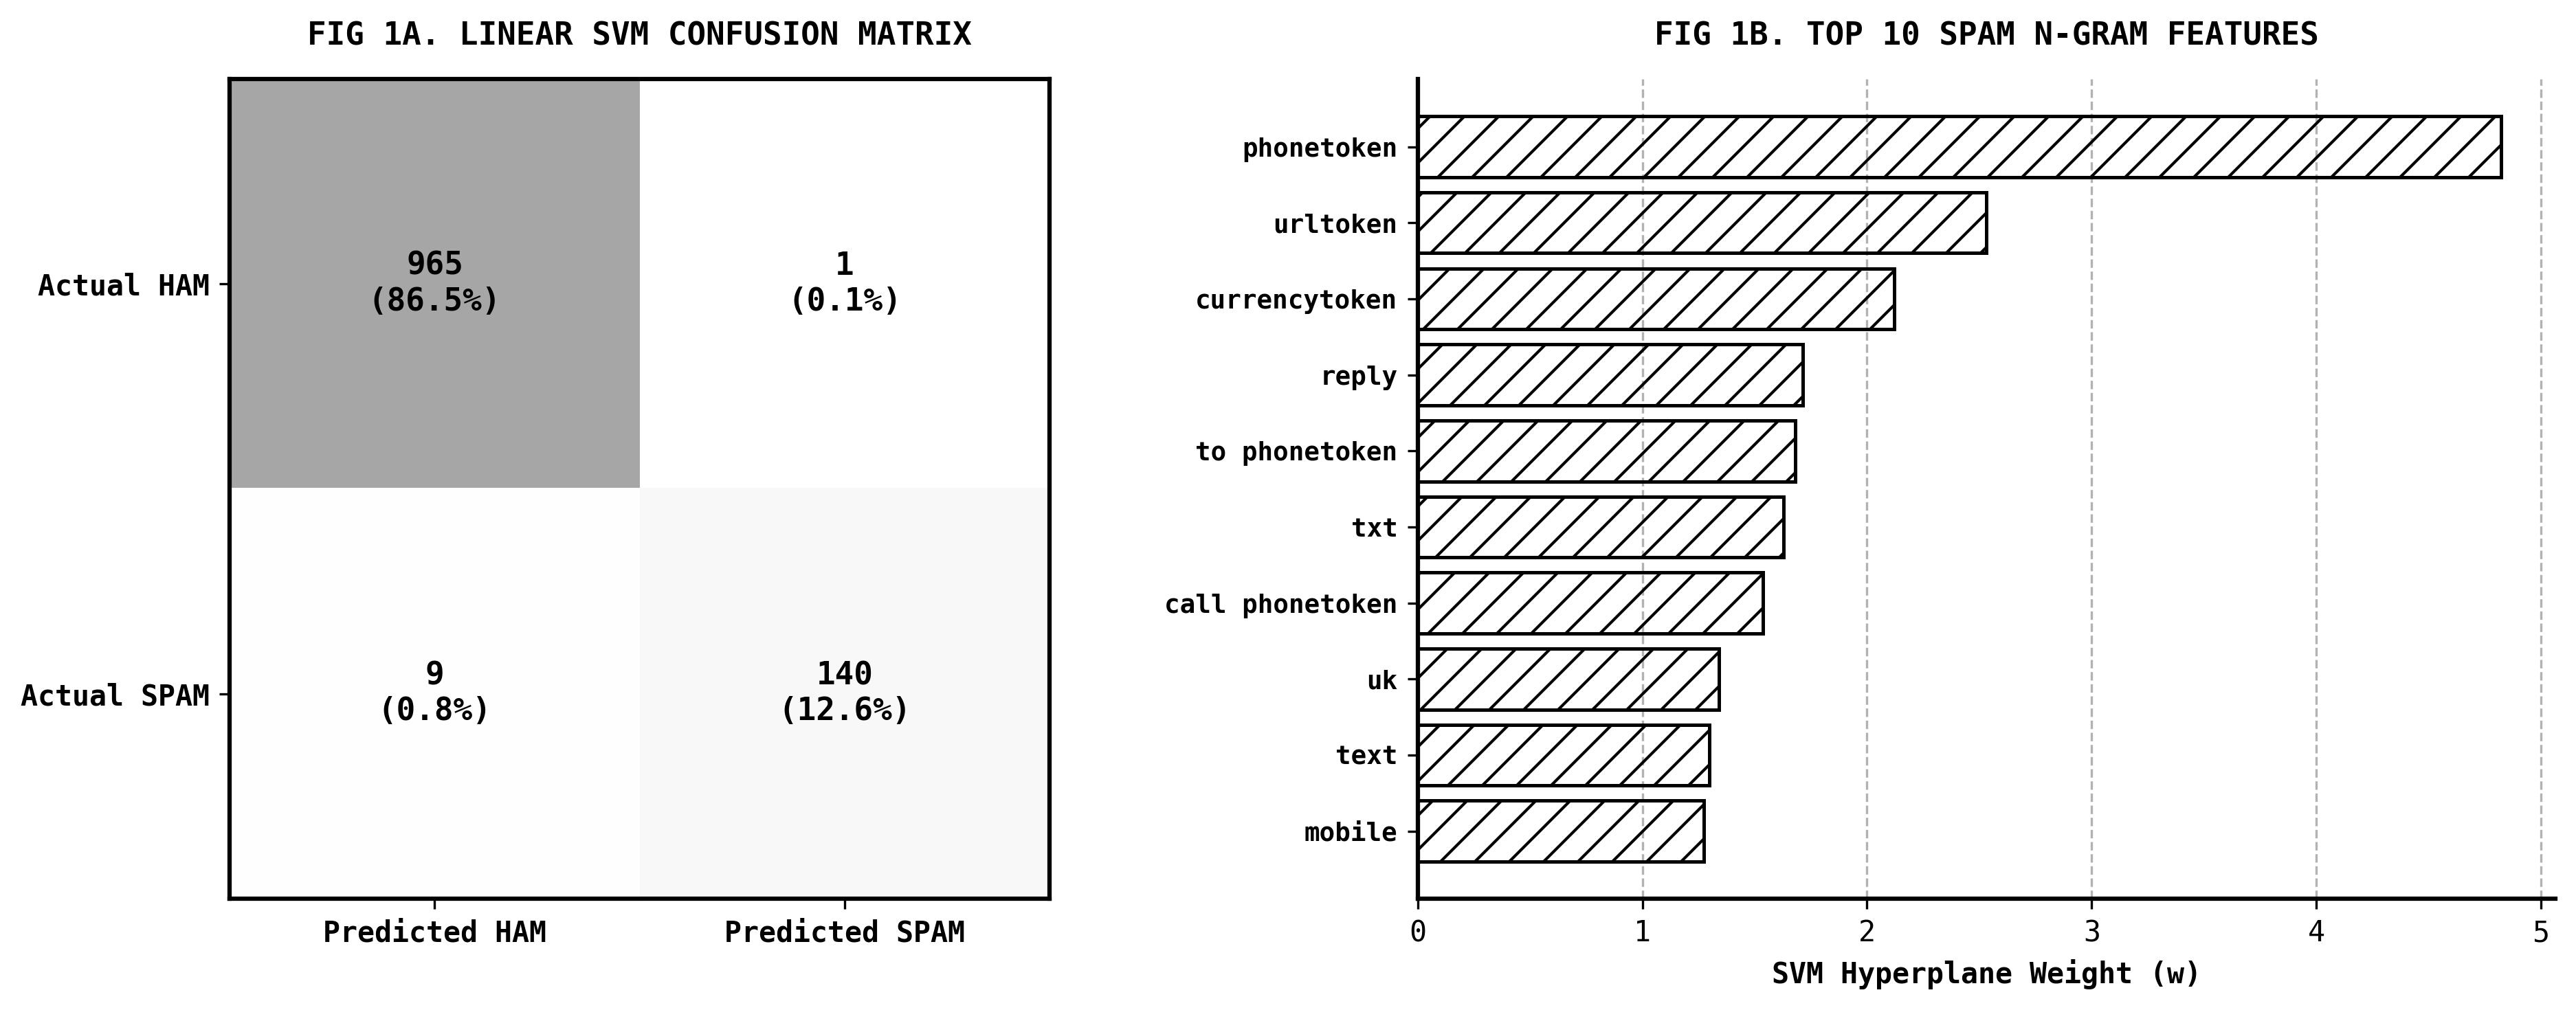

In [4]:
# Generates high-contrast monochrome (Black & White) technical figures for documentation
plt.rcParams["font.family"] = "monospace"

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=300)
fig.patch.set_facecolor("white")

# --- Panel A: Black & White Confusion Matrix (Linear SVM) ---
cm = confusion_matrix(y_test, svm_preds)
ax1 = axes[0]
ax1.imshow(cm, cmap="Greys", alpha=0.35)
ax1.set_xticks([0, 1])
ax1.set_yticks([0, 1])
ax1.set_xticklabels(["Predicted HAM", "Predicted SPAM"], fontsize=10, fontweight="bold")
ax1.set_yticklabels(["Actual HAM", "Actual SPAM"], fontsize=10, fontweight="bold")
ax1.set_title("FIG 1A. LINEAR SVM CONFUSION MATRIX", fontsize=11, fontweight="bold", pad=12)

for i in range(2):
    for j in range(2):
        ax1.text(
            j, i, f"{cm[i, j]}\n({cm[i, j]/cm.sum()*100:.1f}%)",
            ha="center", va="center", color="black", fontsize=11, fontweight="bold"
        )

for spine in ax1.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.5)

# --- Panel B: Black & White Top Predictive N-Grams Sketch ---
svm_pipe = trained_pipelines["Linear SVM"]
feature_names = np.array(svm_pipe.named_steps["tfidf"].get_feature_names_out())
coefs = svm_pipe.named_steps["classifier"].coef_.ravel()
top_spam_idx = np.argsort(coefs)[-10:]

ax2 = axes[1]
y_pos = np.arange(len(top_spam_idx))
ax2.barh(y_pos, coefs[top_spam_idx], color="white", edgecolor="black", hatch="//", linewidth=1.2)
ax2.set_yticks(y_pos)
ax2.set_yticklabels(feature_names[top_spam_idx], fontsize=9, fontweight="bold")
ax2.set_xlabel("SVM Hyperplane Weight (w)", fontsize=10, fontweight="bold")
ax2.set_title("FIG 1B. TOP 10 SPAM N-GRAM FEATURES", fontsize=11, fontweight="bold", pad=12)
ax2.grid(axis="x", linestyle="--", color="black", alpha=0.3)

for spine in ["top", "right"]:
    ax2.spines[spine].set_visible(False)
for spine in ["bottom", "left"]:
    ax2.spines[spine].set_edgecolor("black")
    ax2.spines[spine].set_linewidth(1.5)

plt.tight_layout()
plt.savefig("/content/sms_spam_bw_technical_sketch.png", dpi=300, facecolor="white")
plt.show()

In [5]:
def predict_sms(messages: list[str], model_name: str = "Linear SVM") -> pd.DataFrame:
    """Runs end-to-end inference on new unseen SMS strings."""
    pipe = trained_pipelines[model_name]
    cleaned = [clean_sms_text(m) for m in messages]
    preds = pipe.predict(cleaned)
    scores = pipe.decision_function(cleaned) if hasattr(pipe, "decision_function") else None

    return pd.DataFrame({
        "SMS Message": messages,
        "Prediction": ["SPAM" if p == 1 else "HAM" for p in preds],
        "Margin Score": np.round(scores, 3) if scores is not None else "N/A",
    })

sample_sms = [
    "URGENT! Your mobile number has won £2,000 cash prize. Call 08718729758 to claim now!",
    "Hey, are we still meeting at the coffee shop around 5 PM today?",
    "FreeMsg: Claim your 3 hours free talk time now! Reply YES to 86888.",
]

print(predict_sms(sample_sms).to_string(index=False))

                                                                         SMS Message Prediction  Margin Score
URGENT! Your mobile number has won £2,000 cash prize. Call 08718729758 to claim now!       SPAM         2.112
                     Hey, are we still meeting at the coffee shop around 5 PM today?        HAM        -1.175
                 FreeMsg: Claim your 3 hours free talk time now! Reply YES to 86888.       SPAM         1.427
